# 02 - Feature Engineering

### Objective

Transform cleaned NBA player statistics into interpretable measures of playing style.

### Goals

1. Combine validated datasets.
2. Normalize statistical activity.
3. Engineer offensive and defensive style metrics.
4. Evaluate feature quality and redundancy.

### Modeling Philosophy

Playing style and player performance are treated separately.

The style representation of a player focuses on tendencies, actions, usage, responsibilities, and shot selection. Efficiency and performance outcomes are reserved for later player evaluation.

Per 100 possessions is the preferred normalization unit for this analysis because it not only adjusts for playing time differences but also controls for pace and game speed which can vary by team and era.

### Inputs

- Validated NBA datasets

### Outputs

- Player-level engineered statistics
- Playing-style dimensions
- Feature dictionary

In [77]:
import pandas as pd
import numpy as np
import duckdb

from nba_archetypes.config import (PROJECT_ROOT, RAW_DATA_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR, SQL_DIR, MIN_MINUTES)
from nba_archetypes.data_validation import validate_candidate_features
from nba_archetypes.feature_engineering import safe_divide, per_100_calc

# Load eligible players dataset.
eligible_players = pd.read_parquet(INTERIM_DATA_DIR / "eligible_players.parquet")
eligible_ids = set(eligible_players["PLAYER_ID"])

# Load existing raw datasets.
datasets = {file.stem: pd.read_parquet(file) for file in RAW_DATA_DIR.glob("*.parquet")}

### 1. Feature Source Verification

Before engineering our offensive and defensive features, we verify that the necessary raw columns exist, inspect their values, and document the planned calculations.

We will also be documenting whether there are any missing eligible players and we need to inspect whether the minimum, median, and maximum values look plausible for that statistic.

In [20]:
required_columns = [
    # Statistics needed for feature engineering calculations
    "POSS",
    "FGA",

    # Offensive features
    "FG3A",
    "USG_PCT",
    "TOUCHES",
    "AVG_SEC_PER_TOUCH",
    "POTENTIAL_AST",
    "PASSES_MADE",
    "DRIVES",
    "RA_FGA",
    "PULL_UP_FGA",
    "PCT_UAST_FGM",
    "CATCH_SHOOT_FGA",
    "PAINT_TOUCHES",
    "POST_TOUCHES",
    "SCREEN_ASSISTS",
    "OREB_CHANCES",

    #Defensive features
    "DEFLECTIONS",
    "STL",
    "BLK",
    "CONTESTED_SHOTS_3PT",
    "CONTESTED_SHOTS_2PT",
    "DREB_CHANCES"
]

results = []

for column in required_columns:
    found = False
    for dataset_name, df in datasets.items():
        if dataset_name.startswith("playtype_") or dataset_name == "matchup_stats":
            continue
        if column not in df.columns:
            continue
        found = True
        eligible_data = df[df["PLAYER_ID"].isin(eligible_ids)]
        values = pd.to_numeric(eligible_data[column], errors="coerce")

        results.append({
                "column": column,
                "dataset": dataset_name,
                "status": "Found",
                "players": eligible_data["PLAYER_ID"].nunique(),
                "missing": values.isna().sum(),
                "minimum": values.min(),
                "median": values.median(),
                "maximum": values.max()
        })
    if not found:
        results.append({
            "column": column,
            "dataset": None,
            "status": "Missing",
            "players": None,
            "missing": None,
            "minimum": None,
            "median": None,
            "maximum": None
        })

column_report = pd.DataFrame(results)

display(column_report)

multiple_sources = column_report[column_report.duplicated("column", keep=False)]
display(multiple_sources)

,column,dataset,status,players,missing,minimum,median,maximum
0,POSS,advanced_stats,Found,450,0,537.000,2588.500,6040.000
1,FGA,advanced_stats,Found,450,0,60.000,403.000,1543.000
2,FGA,base_stats,Found,450,0,60.000,403.000,1543.000
3,FGA,scoring_stats,Found,450,0,60.000,403.000,1543.000
4,FG3A,base_stats,Found,450,0,0.000,165.500,740.000
5,USG_PCT,advanced_stats,Found,450,0,0.082,0.177,0.368
6,USG_PCT,usage_stats,Found,450,0,0.082,0.177,0.368
7,TOUCHES,painttouch_stats,Found,450,0,234.000,1755.500,6134.000
8,TOUCHES,possessions_stats,Found,450,0,234.000,1755.500,6134.000
9,TOUCHES,posttouch_stats,Found,450,0,234.000,1755.500,6134.000


,column,dataset,status,players,missing,minimum,median,maximum
1,FGA,advanced_stats,Found,450,0,60.000,403.000,1543.000
2,FGA,base_stats,Found,450,0,60.000,403.000,1543.000
3,FGA,scoring_stats,Found,450,0,60.000,403.000,1543.000
5,USG_PCT,advanced_stats,Found,450,0,0.082,0.177,0.368
6,USG_PCT,usage_stats,Found,450,0,0.082,0.177,0.368
7,TOUCHES,painttouch_stats,Found,450,0,234.000,1755.500,6134.000
8,TOUCHES,possessions_stats,Found,450,0,234.000,1755.500,6134.000
9,TOUCHES,posttouch_stats,Found,450,0,234.000,1755.500,6134.000
18,PAINT_TOUCHES,painttouch_stats,Found,450,0,3.000,85.500,823.000
19,PAINT_TOUCHES,possessions_stats,Found,450,0,3.000,85.500,823.000


### 2. Denominator Validation

Rather than feeding the raw totals of the stats we collected above into our model, we are going to convert the raw totals into per 100 possessions or share of field goal attempts with our feature engineering calculations. This is to ensure that our model doesn't improperly weight players based off volume of playing time or pace of play relative to their team.

The denominators for these feature engineering calculations are total possession and total field goal attempts per player so we need to make sure these denominators are statistically valid for our calculations.

We are calculating the approximate possessions per 48 minutes for each player which should land somewhere near 100 on average for statistically valid possession counts. We are also making sure that any field goal attempt shares that we are calculating have less than the total number of field goal attempts for any given player.

In [14]:
base = datasets["base_stats"]
advanced = datasets["advanced_stats"]

exposure = (
    base[["PLAYER_ID", "PLAYER_NAME", "MIN"]]
    .merge(
        advanced[["PLAYER_ID", "MIN", "POSS", "GP"]],
        on="PLAYER_ID",
        suffixes=("_base", "_advanced"),
        validate="one_to_one",
    )
)

exposure = exposure[
    exposure["PLAYER_ID"].isin(eligible_ids)
].copy()

# Check consistency between source minutes.
exposure["minute_difference"] = (
    exposure["MIN_base"] - (exposure["MIN_advanced"] * exposure["GP"])
).abs()

# Approximate possessions per 48 minutes.
exposure["poss_per_48"] = (
    exposure["POSS"] / exposure["MIN_base"] * 48
)

print("Players checked:", len(exposure))
print("Maximum minute difference:", exposure["minute_difference"].max())

display(exposure["poss_per_48"].describe())

Players checked: 450
Maximum minute difference: 3.8733333333334485


count    450.000000
mean     101.659499
std        2.481528
min       95.329092
25%      100.092529
50%      101.699729
75%      103.329634
max      110.245479
Name: poss_per_48, dtype: float64

In [24]:
shot_check = (
    datasets["base_stats"][
        ["PLAYER_ID", "FGA", "FG3A"]
    ]
    .merge(
        datasets["shot_locations"][
            ["PLAYER_ID", "RA_FGA"]
        ],
        on="PLAYER_ID",
        validate="one_to_one",
    )
    .merge(
        datasets["pullupshot_stats"][
            ["PLAYER_ID", "PULL_UP_FGA"]
        ],
        on="PLAYER_ID",
        validate="one_to_one",
    )
)

shot_check = shot_check[
    shot_check["PLAYER_ID"].isin(eligible_ids)
]

checks = {
    "3PA > total FGA":
        (shot_check["FG3A"] > shot_check["FGA"]).sum(),

    "RA FGA > total FGA":
        (shot_check["RA_FGA"] > shot_check["FGA"]).sum(),

    "Pull-up FGA > total FGA":
        (shot_check["PULL_UP_FGA"] > shot_check["FGA"]).sum()
}

display(
    pd.DataFrame(
        checks.items(),
        columns=["check", "violations"]
    )
)

,check,violations
0,3PA > total FGA,0
1,RA FGA > total FGA,0
2,Pull-up FGA > total FGA,0


### 3. Matchup Data Duplicate Check

Checking to see if there are any defender-opponent duplicate pairs.

In [22]:
matchups = datasets["matchup_stats"]

print("Matchup rows:", len(matchups))

print(
    "Duplicate defender-opponent pairs:",
    matchups.duplicated(
        ["DEF_PLAYER_ID", "OFF_PLAYER_ID"]
    ).sum()
)

Matchup rows: 147805
Duplicate defender-opponent pairs: 0


### EXPERIMENTAL

In [6]:
source_names = [
    "base_stats",
    "advanced_stats",
    "possessions_stats",
    "passing_stats",
    "drives_stats",
    "shot_locations",
    "pullupshot_stats",
    "scoring_stats",
    "catchshoot_stats",
    "painttouch_stats",
    "posttouch_stats",
    "hustle_stats",
    "rebounding_stats",
]

source_paths = {name: RAW_DATA_DIR / f"{name}.parquet" for name in source_names}

source_paths["eligible_players"] = (INTERIM_DATA_DIR / "eligible_players.parquet")

missing_files = [
    name for name, path in source_paths.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(f"Missing Parquet files: {missing_files}")

sql_query = (SQL_DIR / "02_style_features.sql").read_text()

with duckdb.connect() as con:
    for view_name, file_path in source_paths.items():
        con.execute(f"""
            CREATE OR REPLACE VIEW {view_name} AS
            SELECT *
            FROM read_parquet('{file_path.as_posix()}')
        """)
    style_features = con.execute(sql_query).df()

display(style_features.head())

,PLAYER_ID,PLAYER_NAME,POSS,FGA,FG3A,STL,BLK,USG_PCT,TOUCHES,AVG_SEC_PER_TOUCH,...,CATCH_SHOOT_FG3A,PAINT_TOUCHES,POST_TOUCHES,SCREEN_ASSISTS,DEFLECTIONS,CONTESTED_SHOTS,CONTESTED_SHOTS_3PT,CONTESTED_SHOTS_2PT,OREB_CHANCES,DREB_CHANCES
0,1631260,AJ Green,4704,618,554,39,8,0.135,2930,3.46,...,414.0,37,0,28,111,306,134,172,66,286
1,1642358,AJ Johnson,968,176,57,11,3,0.195,676,4.97,...,36.0,27,1,3,22,64,30,34,26,58
2,203932,Aaron Gordon,2096,398,157,21,10,0.213,1582,4.11,...,98.0,191,68,36,27,102,35,67,80,197
3,1628988,Aaron Holiday,1618,252,170,27,5,0.159,1041,5.00,...,144.0,6,4,6,39,102,53,49,22,65
4,1630174,Aaron Nesmith,2871,512,277,26,23,0.190,2097,3.14,...,220.0,51,11,27,50,250,100,150,86,192


In [7]:
missing_report = (
    style_features
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_report[missing_report > 0]
)

validate_candidate_features(style_features, eligible_players)

CATCH_SHOOT_FG3A    13
dtype: int64

In [8]:
output_path = (INTERIM_DATA_DIR / "raw_style_features.parquet")

style_features.to_parquet(output_path, index=False)

In [ ]:
per_100_features = {
    # Offense
    "TOUCHES": "TOUCHES_PER_100",
    "AST_ADJ": "AST_ADJ_PER_100",
    "DRIVES": "DRIVES_PER_100",
    "RA_FGA": "RA_FGA_PER_100",
    "PULL_UP_FGA": "PULL_UP_FGA_PER_100",
    "FG3A": "3PT_FGA_PER_100",
    "CATCH_SHOOT_FG3A": "CATCH_SHOOT_3PT_FGA_PER_100",
    "PAINT_TOUCHES": "PAINT_TOUCHES_PER_100",
    "POST_TOUCHES": "POST_TOUCHES_PER_100",
    "SCREEN_ASSISTS": "SCREEN_ASSISTS_PER_100",
    "OREB_CHANCES": "OREB_CHANCES_PER_100",

    # Defense
    "DEFLECTIONS": "DEFLECTIONS_PER_100",
    "STL": "STL_PER_100",
    "CONTESTED_SHOTS_2PT": "CONTESTED_2PT_PER_100",
    "BLK": "BLK_PER_100",
    "DREB_CHANCES": "DREB_CHANCES_PER_100"
}

def engineer_style_features(raw_features: pd.DataFrame, per_100_features: dict) -> pd.DataFrame:
    df = raw_features.copy()

    df.loc[df["CATCH_SHOOT_FG3A"].isna(), "CATCH_SHOOT_FG3A"] = 0

    for column, new_feature in per_100_features.items():
        df[new_feature] = per_100_calc(df[column], df["POSS"])
    
    df["3PT_FGA_SHARE"] = safe_divide(df["FG3A"], df["FGA"])
    df["CONTESTED_3PT_SHARE"] = safe_divide(df["CONTESTED_SHOTS_3PT"], df["CONTESTED_SHOTS"])

    return df

In [15]:
style_features = pd.read_parquet(INTERIM_DATA_DIR / "raw_style_features.parquet")

candidate_features = engineer_style_features(style_features, per_100_features)

print("Players:", len(candidate_features))
print("Engineered features:", len(per_100_features) + 2)
print("Total candidate features:", len(per_100_features) + 5)

validate_candidate_features(candidate_features, eligible_players)

display(candidate_features.head())

Players: 450
Engineered features: 19
Total candidate features: 22


,PLAYER_ID,PLAYER_NAME,POSS,FGA,FG3A,STL,BLK,USG_PCT,TOUCHES,AVG_SEC_PER_TOUCH,...,POST_TOUCHES_PER_100,SCREEN_ASSISTS_PER_100,OREB_CHANCES_PER_100,DEFLECTIONS_PER_100,STL_PER_100,CONTESTED_2PT_PER_100,BLK_PER_100,DREB_CHANCES_PER_100,3PT_FGA_SHARE,CONTESTED_3PT_SHARE
0,1631260,AJ Green,4704,618,554,39,8,0.135,2930,3.46,...,0.000000,0.595238,1.403061,2.359694,0.829082,3.656463,0.170068,6.079932,0.896440,0.437908
1,1642358,AJ Johnson,968,176,57,11,3,0.195,676,4.97,...,0.103306,0.309917,2.685950,2.272727,1.136364,3.512397,0.309917,5.991736,0.323864,0.468750
2,203932,Aaron Gordon,2096,398,157,21,10,0.213,1582,4.11,...,3.244275,1.717557,3.816794,1.288168,1.001908,3.196565,0.477099,9.398855,0.394472,0.343137
3,1628988,Aaron Holiday,1618,252,170,27,5,0.159,1041,5.00,...,0.247219,0.370828,1.359703,2.410383,1.668727,3.028430,0.309023,4.017305,0.674603,0.519608
4,1630174,Aaron Nesmith,2871,512,277,26,23,0.190,2097,3.14,...,0.383142,0.940439,2.995472,1.741553,0.905608,5.224660,0.801115,6.687565,0.541016,0.400000


In [17]:
feature_columns = (
    list(per_100_features.values())
    + [
        "3PT_FGA_SHARE",
        "CONTESTED_3PT_SHARE",
        "USG_PCT",
        "AVG_SEC_PER_TOUCH",
        "PCT_UAST_FGM",
    ]
)

missing = (
    candidate_features[feature_columns]
    .isna()
    .sum()
)

display(missing[missing > 0])

Series([], dtype: int64)

In [18]:
for column in ["3PT_FGA_SHARE", "CONTESTED_3PT_SHARE"]:

    invalid = (
        (candidate_features[column] < 0)
        | (candidate_features[column] > 1)
    )

    assert not invalid.any(), (
        f"Invalid values in {column}"
    )

print("Share checks passed.")

Share checks passed.


In [ ]:
offensive_groups = {
    "Ball Dominance": [
        "USG_PCT",
        "TOUCHES_PER_100",
        "AVG_SEC_PER_TOUCH",
    ],
    "Playmaking": [
        "PASSES_PER_100",
        "AST_ADJ_PER_100",
    ],
    "Rim Pressure": [
        "DRIVES_PER_100",
        "RA_FGA_PER_100",
    ],
    "On-Ball Creation": [
        "PULL_UP_FGA_PER_100",
        "PCT_UAST_FGM",
    ],
    "Perimeter Shooting": [
        "3PT_FGA_SHARE",
        "3PT_FGA_PER_100",
        "CATCH_SHOOT_3PT_FGA_PER_100",
    ],
    "Interior Offense": [
        "PAINT_TOUCHES_PER_100",
        "POST_TOUCHES_PER_100",
        "SCREEN_ASSISTS_PER_100",
    ],
    "Offensive Rebounding": [
        "OREB_CHANCES_PER_100",
    ],
}

defensive_groups = {
    "Defensive Disruption": [
        "DEFLECTIONS_PER_100",
        "STL_PER_100",
    ],
    "Perimeter Defense": [
        "CONTESTED_3PT_SHARE",
    ],
    "Interior Defense": [
        "CONTESTED_2PT_PER_100",
        "BLK_PER_100",
    ],
    "Defensive Rebounding": [
        "DREB_CHANCES_PER_100",
    ],
}

feature_groups = offensive_groups | defensive_groups

summary_rows = []
for dimension, group in feature_groups.items():
    for feature in group:

        values = candidate_features[feature]

        summary_rows.append({
            "dimension": dimension,
            "feature": feature,
            "missing_pct": round(
                values.isna().mean() * 100, 2
            ),
            "zero_pct": round(
                values.eq(0).mean() * 100, 2
            ),
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "skewness": values.skew(),
            "min": values.min(),
            "max": values.max(),
        })

feature_summary = pd.DataFrame(summary_rows)

display(feature_summary.round(3))

,dimension,feature,missing_pct,zero_pct,mean,median,std,skewness,min,max
0,Ball Dominance,USG_PCT,0.0,0.00,0.185,0.177,0.053,0.702,0.082,0.368
1,Ball Dominance,TOUCHES_PER_100,0.0,0.00,71.670,68.298,18.576,0.452,32.486,126.370
2,Ball Dominance,AVG_SEC_PER_TOUCH,0.0,0.00,3.506,3.210,1.345,0.501,1.110,6.990
3,Playmaking,PASSES_PER_100,0.0,0.00,55.397,52.784,15.602,0.534,23.189,104.165
4,Playmaking,POTENTIAL_AST_PER_100,0.0,0.00,8.927,7.490,4.811,1.024,1.763,25.026
5,Rim Pressure,DRIVES_PER_100,0.0,0.00,11.916,10.466,8.053,0.779,0.065,38.994
6,Rim Pressure,RA_FGA_PER_100,0.0,0.00,4.867,4.529,2.486,0.799,0.075,18.585
7,On-Ball Creation,PULL_UP_FGA_PER_100,0.0,1.56,3.674,2.705,3.487,1.278,0.000,17.465
8,On-Ball Creation,PCT_UAST_FGM,0.0,0.22,0.327,0.310,0.155,0.463,0.000,0.803
9,Perimeter Shooting,3PT_FGA_SHARE,0.0,2.89,0.424,0.443,0.203,-0.295,0.000,0.958


In [71]:
feature_name = "BLK_PER_100"

top_players = candidate_features.nlargest(
    10, feature_name
)[
    [
        "PLAYER_NAME",
        feature_name,
    ]
]

display(top_players)

,PLAYER_NAME,BLK_PER_100
434,Victor Wembanyama,4.953483
196,Jay Huff,4.157609
373,Robert Williams III,4.027778
323,Moussa Cisse,3.933566
266,Khaman Maluach,3.877791
211,Joan Beringer,3.741007
443,Yves Missi,3.714601
125,Dylan Cardwell,3.552492
445,Zach Edey,3.482587
442,Yanic Konan Niederhäuser,3.436426


In [35]:
from itertools import combinations

pearson_corr = candidate_features[feature_columns].corr(method="pearson")

spearman_corr = candidate_features[feature_columns].corr(method="spearman")

correlation_rows = []

for feature_a, feature_b in combinations(
    feature_columns, 2
):

    pearson = pearson_corr.loc[
        feature_a, feature_b
    ]

    spearman = spearman_corr.loc[
        feature_a, feature_b
    ]

    if abs(pearson) >= 0.80 or abs(spearman) >= 0.80:
        correlation_rows.append({
            "feature_1": feature_a,
            "feature_2": feature_b,
            "pearson": pearson,
            "spearman": spearman,
        })

high_correlations = pd.DataFrame(
    correlation_rows,
    columns=[
        "feature_1",
        "feature_2",
        "pearson",
        "spearman",
    ],
)

display(high_correlations.round(3))

,feature_1,feature_2,pearson,spearman
0,TOUCHES_PER_100,PASSES_PER_100,0.919,0.919
1,TOUCHES_PER_100,POTENTIAL_AST_PER_100,0.852,0.847
2,PASSES_PER_100,POTENTIAL_AST_PER_100,0.823,0.820
3,DRIVES_PER_100,AVG_SEC_PER_TOUCH,0.814,0.825
4,3PT_FGA_PER_100,CATCH_SHOOT_3PT_FGA_PER_100,0.841,0.806
5,3PT_FGA_PER_100,3PT_FGA_SHARE,0.841,0.805
6,CATCH_SHOOT_3PT_FGA_PER_100,3PT_FGA_SHARE,0.876,0.844
7,PAINT_TOUCHES_PER_100,SCREEN_ASSISTS_PER_100,0.845,0.709
8,PAINT_TOUCHES_PER_100,OREB_CHANCES_PER_100,0.917,0.918
9,SCREEN_ASSISTS_PER_100,OREB_CHANCES_PER_100,0.804,0.678


In [69]:
feature_a = "CONTESTED_2PT_PER_100"
feature_b = "BLK_PER_100"

comparison = candidate_features[
    ["PLAYER_NAME", feature_a, feature_b]
].copy()

# Standardize temporarily for comparing two features.
comparison["A_Z"] = (
    (comparison[feature_a] - comparison[feature_a].mean())
    / comparison[feature_a].std()
)

comparison["B_Z"] = (
    (comparison[feature_b] - comparison[feature_b].mean())
    / comparison[feature_b].std()
)

# Positive differences identify players who are unusually
# high in A relative to B.
comparison["DIFFERENCE"] = (
    comparison["A_Z"] - comparison["B_Z"]
)

display(
    comparison.nlargest(10, "DIFFERENCE")[
        ["PLAYER_NAME", feature_a, feature_b, "DIFFERENCE"]
    ]
)

display(
    comparison.nsmallest(10, "DIFFERENCE")[
        ["PLAYER_NAME", feature_a, feature_b, "DIFFERENCE"]
    ]
)

,PLAYER_NAME,CONTESTED_2PT_PER_100,BLK_PER_100,DIFFERENCE
296,Luke Kornet,16.715831,2.130449,2.194536
312,Micah Potter,10.794603,0.749625,2.040065
367,Quinten Post,12.815297,1.423922,1.845088
157,Ivica Zubac,11.529332,1.356392,1.528131
441,Yang Hansen,11.926606,1.529052,1.440898
309,Maxi Kleber,10.152284,1.116751,1.392818
124,Dwight Powell,9.791984,1.065449,1.343510
413,Tony Bradley,8.455115,0.730689,1.336692
113,Donovan Clingan,17.045199,2.923319,1.329733
200,Jaylin Williams,11.528545,1.546961,1.295445


,PLAYER_NAME,CONTESTED_2PT_PER_100,BLK_PER_100,DIFFERENCE
434,Victor Wembanyama,10.912748,4.953483,-3.050778
373,Robert Williams III,10.092593,4.027778,-2.176356
318,Mitchell Robinson,6.736402,2.928870,-1.878177
306,Matisse Thybulle,1.934236,1.547389,-1.684349
443,Yves Missi,10.555351,3.714601,-1.650670
26,Ausar Thompson,4.045512,1.744627,-1.269320
258,Keon Ellis,3.067485,1.485308,-1.256726
35,Bilal Coulibaly,3.949843,1.692790,-1.235801
104,Derrick Jones Jr.,4.400716,1.788909,-1.213032
323,Moussa Cisse,13.024476,3.933566,-1.151021


In [48]:
x = candidate_features["TOUCHES_PER_100"]
y = candidate_features["PASSES_PER_100"]

# Fit a simple linear relationship.
slope = x.cov(y) / x.var()
intercept = y.mean() - slope * x.mean()

# Expected number of passes based on touches.
expected_passes = intercept + slope * x

# Passes above or below expectation.
candidate_features["TOUCH_ADJUSTED_PASSING"] = (
    y - expected_passes
)

display(
    candidate_features.nlargest(
        10, "TOUCH_ADJUSTED_PASSING"
    )[
        [
            "PLAYER_NAME",
            "TOUCHES_PER_100",
            "PASSES_PER_100",
            "TOUCH_ADJUSTED_PASSING",
        ]
    ]
)

display(
    candidate_features.nsmallest(
        10, "TOUCH_ADJUSTED_PASSING"
    )[
        [
            "PLAYER_NAME",
            "TOUCHES_PER_100",
            "PASSES_PER_100",
            "TOUCH_ADJUSTED_PASSING",
        ]
    ]
)

,PLAYER_NAME,TOUCHES_PER_100,PASSES_PER_100,TOUCH_ADJUSTED_PASSING
376,Royce O'Neale,67.624357,70.025729,17.752071
291,Lonzo Ball,83.887147,82.570533,17.742532
335,Nicolas Batum,45.335332,52.791308,17.724048
432,Tyus Jones,91.880135,86.901885,15.903559
420,Trendon Watford,93.880837,87.332260,14.789457
119,Draymond Green,107.671026,97.082495,13.894118
200,Jaylin Williams,86.924494,81.031308,13.858575
273,Kris Dunn,80.679825,75.833333,13.481281
315,Mike Conley,86.528497,80.028262,13.161225
16,Andre Jackson Jr.,81.036514,75.736160,13.108756


,PLAYER_NAME,TOUCHES_PER_100,PASSES_PER_100,TOUCH_ADJUSTED_PASSING
197,Jaylen Brown,94.389704,53.549165,-19.386466
107,Devin Booker,89.725421,50.797166,-18.537791
392,Shai Gilgeous-Alexander,92.118432,54.065888,-17.116395
248,Kawhi Leonard,82.025913,46.619552,-16.771636
110,Dillon Brooks,61.938202,31.685393,-16.198740
139,Giannis Antetokounmpo,114.979196,73.185391,-15.644654
172,Jalen Green,83.149971,48.755067,-15.503858
343,Norman Powell,66.499472,35.929250,-15.476034
398,Stephen Curry,94.013227,57.883745,-14.761257
293,Luka Dončić,109.825146,70.587011,-14.264276


In [50]:
display(round(candidate_features["TOUCH_ADJUSTED_PASSING"].corr(candidate_features["USG_PCT"]),3))
display(round(candidate_features["TOUCH_ADJUSTED_PASSING"].corr(candidate_features["POTENTIAL_AST_PER_100"]),3))
display(round(candidate_features["TOUCH_ADJUSTED_PASSING"].corr(candidate_features["TOUCHES_PER_100"]),3))
display(round(candidate_features["TOUCH_ADJUSTED_PASSING"].corr(candidate_features["AVG_SEC_PER_TOUCH"]),3))

np.float64(-0.655)

np.float64(0.101)

np.float64(0.0)

np.float64(-0.075)

In [52]:
candidate_features["POTENTIAL_AST_PER_PASS"] = (
    candidate_features["POTENTIAL_AST_PER_100"]
    / candidate_features["PASSES_PER_100"]
)

# Examine the highest-ranked players.
display(
    candidate_features.nlargest(
        15, "POTENTIAL_AST_PER_PASS"
    )[
        [
            "PLAYER_NAME",
            "TOUCH_ADJUSTED_PASSING",
            "POTENTIAL_AST_PER_100",
            "POTENTIAL_AST_PER_PASS",
            "USG_PCT",
        ]
    ]
)

# Examine relationships with existing features.
compare_columns = [
    "TOUCH_ADJUSTED_PASSING",
    "POTENTIAL_AST_PER_100",
    "POTENTIAL_AST_PER_PASS",
    "USG_PCT",
    "TOUCHES_PER_100",
]

display(
    candidate_features[compare_columns]
    .corr()
    .round(3)
)

,PLAYER_NAME,TOUCH_ADJUSTED_PASSING,POTENTIAL_AST_PER_100,POTENTIAL_AST_PER_PASS,USG_PCT
30,Baylor Scheierman,5.704285,25.026069,0.571429,0.117
197,Jaylen Brown,-19.386466,18.479791,0.345100,0.351
415,Trae Young,-4.838417,24.249423,0.334395,0.262
392,Shai Gilgeous-Alexander,-17.116395,17.994162,0.332819,0.323
107,Devin Booker,-18.537791,16.895483,0.332607,0.307
97,DeMar DeRozan,-10.024092,12.253743,0.320949,0.222
158,Ja Morant,-6.358996,23.320158,0.319264,0.305
55,Cade Cunningham,-3.741238,23.044907,0.273816,0.296
91,Darius Garland,-5.275820,18.592437,0.268861,0.266
267,Khris Middleton,-7.248906,10.519564,0.266884,0.198


,TOUCH_ADJUSTED_PASSING,POTENTIAL_AST_PER_100,POTENTIAL_AST_PER_PASS,USG_PCT,TOUCHES_PER_100
TOUCH_ADJUSTED_PASSING,1.000,0.101,-0.182,-0.655,0.000
POTENTIAL_AST_PER_100,0.101,1.000,0.845,0.493,0.852
POTENTIAL_AST_PER_PASS,-0.182,0.845,1.000,0.474,0.539
USG_PCT,-0.655,0.493,0.474,1.000,0.668
TOUCHES_PER_100,0.000,0.852,0.539,0.668,1.000


In [61]:
passing = datasets["passing_stats"]

adjusted_assists = (
    passing[[
        "PLAYER_ID",
        "AST",
        "SECONDARY_AST",
        "AST_ADJ",
    ]]
    .merge(
        datasets["advanced_stats"][["PLAYER_ID", "POSS"]],
        on="PLAYER_ID",
        validate="one_to_one",
    )
)

adjusted_assists = adjusted_assists[
    adjusted_assists["PLAYER_ID"].isin(eligible_ids)
].copy()

adjusted_assists["AST_ADJ_PER_100"] = (
    adjusted_assists["AST_ADJ"]
    / adjusted_assists["POSS"] * 100
)

comparison = candidate_features.merge(
    adjusted_assists[["PLAYER_ID", "AST_ADJ_PER_100"]],
    on="PLAYER_ID",
    validate="one_to_one",
)

display(
    comparison.nlargest(15, "AST_ADJ_PER_100")[
        [
            "PLAYER_NAME",
            "POTENTIAL_AST_PER_100",
            "AST_ADJ_PER_100",
            "TOUCH_ADJUSTED_PASSING",
        ]
    ]
)

columns = [
    "POTENTIAL_AST_PER_100",
    "AST_ADJ_PER_100",
    "TOUCH_ADJUSTED_PASSING",
    "TOUCHES_PER_100",
    "USG_PCT",
]

display(
    comparison[columns].corr().round(3)
)

,PLAYER_NAME,POTENTIAL_AST_PER_100,AST_ADJ_PER_100,TOUCH_ADJUSTED_PASSING
336,Nikola Jokić,22.476308,17.676143,-0.054361
415,Trae Young,24.249423,17.436490,-4.838417
55,Cade Cunningham,23.044907,17.349398,-3.741238
402,T.J. McConnell,24.509335,17.041647,7.460317
158,Ja Morant,23.320158,15.652174,-6.358996
229,Josh Giddey,23.354565,15.578556,8.433491
151,Isaiah Collier,23.944090,15.192950,10.013083
281,LaMelo Ball,19.909394,15.188364,-6.709048
382,Ryan Nembhard,20.392628,14.903846,4.863475
424,Ty Jerome,17.453505,14.735336,-12.374737


,POTENTIAL_AST_PER_100,AST_ADJ_PER_100,TOUCH_ADJUSTED_PASSING,TOUCHES_PER_100,USG_PCT
POTENTIAL_AST_PER_100,1.000,0.962,0.101,0.852,0.493
AST_ADJ_PER_100,0.962,1.000,0.082,0.881,0.525
TOUCH_ADJUSTED_PASSING,0.101,0.082,1.000,0.000,-0.655
TOUCHES_PER_100,0.852,0.881,0.000,1.000,0.668
USG_PCT,0.493,0.525,-0.655,0.668,1.000


In [75]:
x = candidate_features["PAINT_TOUCHES_PER_100"]
y = candidate_features["OREB_CHANCES_PER_100"]

# Expected OREB chances from paint-touch activity.
slope = x.cov(y) / x.var()
intercept = y.mean() - slope * x.mean()

expected_oreb = intercept + slope * x

candidate_features["PAINT_ADJUSTED_OREB"] = (
    y - expected_oreb
)

comparison = [
    "PLAYER_NAME",
    "PAINT_TOUCHES_PER_100",
    "OREB_CHANCES_PER_100",
    "PAINT_ADJUSTED_OREB",
]

print("Highest adjusted offensive rebounding:")
display(
    candidate_features.nlargest(10, "PAINT_ADJUSTED_OREB")[
        comparison
    ]
)

print("Lowest adjusted offensive rebounding:")
display(
    candidate_features.nsmallest(10, "PAINT_ADJUSTED_OREB")[
        comparison
    ]
)

columns = [
    "PAINT_ADJUSTED_OREB",
    "OREB_CHANCES_PER_100",
    "PAINT_TOUCHES_PER_100",
    "POST_TOUCHES_PER_100",
    "SCREEN_ASSISTS_PER_100",
]

display(candidate_features[columns].corr().round(3))

Highest adjusted offensive rebounding:


,PLAYER_NAME,PAINT_TOUCHES_PER_100,OREB_CHANCES_PER_100,PAINT_ADJUSTED_OREB
324,Moussa Diabaté,16.081187,14.467864,4.419292
68,Chaney Johnson,6.868132,9.065934,4.119807
323,Moussa Cisse,16.346154,14.248252,4.052934
264,Kevon Looney,10.151515,10.757576,3.993020
318,Mitchell Robinson,15.313808,13.556485,3.932909
266,Khaman Maluach,12.338425,11.868390,3.892663
326,Myron Gardner,5.228758,7.843137,3.804940
282,Lachlan Olbrich,10.091743,10.222805,3.491352
349,Oscar Tshiebwe,18.609407,14.826176,3.377406
400,Steven Adams,17.458194,14.046823,3.235626


Lowest adjusted offensive rebounding:


,PLAYER_NAME,PAINT_TOUCHES_PER_100,OREB_CHANCES_PER_100,PAINT_ADJUSTED_OREB
191,Jarrett Allen,17.118227,6.773399,-3.849514
195,Jaxson Hayes,15.573123,6.600791,-3.166401
99,Deandre Ayton,16.551724,7.192118,-3.117050
139,Giannis Antetokounmpo,14.424411,6.102635,-3.028368
310,Maxime Raynaud,13.606755,5.741858,-2.936305
338,Nikola Vučević,12.003098,5.059370,-2.730643
445,Zach Edey,25.041459,12.437811,-2.573207
132,Evan Mobley,12.798907,5.852881,-2.377874
2,Aaron Gordon,9.112595,3.816794,-2.372379
434,Victor Wembanyama,11.088760,4.928338,-2.355290


,PAINT_ADJUSTED_OREB,OREB_CHANCES_PER_100,PAINT_TOUCHES_PER_100,POST_TOUCHES_PER_100,SCREEN_ASSISTS_PER_100
PAINT_ADJUSTED_OREB,1.000,0.399,-0.000,-0.319,0.071
OREB_CHANCES_PER_100,0.399,1.000,0.917,0.320,0.804
PAINT_TOUCHES_PER_100,-0.000,0.917,1.000,0.487,0.845
POST_TOUCHES_PER_100,-0.319,0.320,0.487,1.000,0.371
SCREEN_ASSISTS_PER_100,0.071,0.804,0.845,0.371,1.000


### FINALIZE FEATURES

In [78]:
source_names = [
    "base_stats",
    "advanced_stats",
    "possessions_stats",
    "passing_stats",
    "drives_stats",
    "shot_locations",
    "pullupshot_stats",
    "scoring_stats",
    "catchshoot_stats",
    "painttouch_stats",
    "posttouch_stats",
    "hustle_stats",
    "rebounding_stats",
]

source_paths = {name: RAW_DATA_DIR / f"{name}.parquet" for name in source_names}

source_paths["eligible_players"] = (INTERIM_DATA_DIR / "eligible_players.parquet")

missing_files = [
    name for name, path in source_paths.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(f"Missing Parquet files: {missing_files}")

sql_query = (SQL_DIR / "02_style_features.sql").read_text()

with duckdb.connect() as con:
    for view_name, file_path in source_paths.items():
        con.execute(f"""
            CREATE OR REPLACE VIEW {view_name} AS
            SELECT *
            FROM read_parquet('{file_path.as_posix()}')
        """)
    style_features = con.execute(sql_query).df()

display(style_features.head())

output_path = (INTERIM_DATA_DIR / "raw_style_features.parquet")

style_features.to_parquet(output_path, index=False)

,PLAYER_ID,PLAYER_NAME,POSS,FGA,FG3A,STL,BLK,USG_PCT,TOUCHES,AVG_SEC_PER_TOUCH,...,CATCH_SHOOT_FG3A,PAINT_TOUCHES,POST_TOUCHES,SCREEN_ASSISTS,DEFLECTIONS,CONTESTED_SHOTS,CONTESTED_SHOTS_3PT,CONTESTED_SHOTS_2PT,OREB_CHANCES,DREB_CHANCES
0,1631260,AJ Green,4704,618,554,39,8,0.135,2930,3.46,...,414.0,37,0,28,111,306,134,172,66,286
1,1642358,AJ Johnson,968,176,57,11,3,0.195,676,4.97,...,36.0,27,1,3,22,64,30,34,26,58
2,203932,Aaron Gordon,2096,398,157,21,10,0.213,1582,4.11,...,98.0,191,68,36,27,102,35,67,80,197
3,1628988,Aaron Holiday,1618,252,170,27,5,0.159,1041,5.00,...,144.0,6,4,6,39,102,53,49,22,65
4,1630174,Aaron Nesmith,2871,512,277,26,23,0.190,2097,3.14,...,220.0,51,11,27,50,250,100,150,86,192


In [116]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

per_100_features = {
    # Offense
    "TOUCHES": "TOUCHES_PER_100",
    "AST_ADJ": "AST_ADJ_PER_100",
    "PASSES_MADE": "PASSES_PER_100",
    "DRIVES": "DRIVES_PER_100",
    "RA_FGA": "RA_FGA_PER_100",
    "PULL_UP_FGA": "PULL_UP_FGA_PER_100",
    "CATCH_SHOOT_FG3A": "CATCH_SHOOT_3PA_PER_100",
    "PAINT_TOUCHES": "PAINT_TOUCHES_PER_100",
    "POST_TOUCHES": "POST_TOUCHES_PER_100",
    "SCREEN_ASSISTS": "SCREEN_ASSISTS_PER_100",
    "OREB_CHANCES": "OREB_CHANCES_PER_100",

    # Defense
    "DEFLECTIONS": "DEFLECTIONS_PER_100",
    "CONTESTED_SHOTS_2PT": "CONTESTED_2PT_PER_100",
    "BLK": "BLK_PER_100",
    "DREB_CHANCES": "DREB_CHANCES_PER_100"
}

adjustments = [
    (
        "TOUCHES_PER_100",
        "PASSES_PER_100",
        "TOUCH_ADJUSTED_PASSING",
    ),
    (
        "PAINT_TOUCHES_PER_100",
        "OREB_CHANCES_PER_100",
        "PAINT_ADJUSTED_OREB",
    ),
]

log_features = [
    "POST_TOUCHES_PER_100",
    "BLK_PER_100",
    "SCREEN_ASSISTS_PER_100",
    "OREB_CHANCES_PER_100",
    "PAINT_TOUCHES_PER_100",
    "CONTESTED_2PT_PER_100",
    "PULL_UP_FGA_PER_100",
    "DEFLECTIONS_PER_100",
]

def engineer_style_features(raw_features: pd.DataFrame, per_100_features: dict, adjustment_features: list) -> pd.DataFrame:
    df = raw_features.copy()

    df.loc[df["CATCH_SHOOT_FG3A"].isna(), "CATCH_SHOOT_FG3A"] = 0

    for column, new_feature in per_100_features.items():
        df[new_feature] = per_100_calc(df[column], df["POSS"])

    adjustment_models = {}
    for predictor, response, output in adjustment_features:
        lm = LinearRegression()
        lm.fit(df[[predictor]], df[response])
        df[output] = df[response] - lm.predict(df[[predictor]])
        adjustment_models[output] = lm
    
    df["3PA_SHARE"] = safe_divide(df["FG3A"], df["FGA"])
    df["CONTESTED_3PT_SHARE"] = safe_divide(df["CONTESTED_SHOTS_3PT"], df["CONTESTED_SHOTS"])

    return df

In [117]:
style_features = pd.read_parquet(INTERIM_DATA_DIR / "raw_style_features.parquet")

candidate_features = engineer_style_features(style_features, per_100_features, adjustments)

print("Players:", len(candidate_features))
print("Engineered features:", len(per_100_features) + 2)
print("Total candidate features:", len(per_100_features) + 5)

validate_candidate_features(candidate_features, eligible_players)

display(candidate_features.head())

Players: 450
Engineered features: 17
Total candidate features: 20


,PLAYER_ID,PLAYER_NAME,POSS,FGA,FG3A,STL,BLK,USG_PCT,TOUCHES,AVG_SEC_PER_TOUCH,...,SCREEN_ASSISTS_PER_100,OREB_CHANCES_PER_100,DEFLECTIONS_PER_100,CONTESTED_2PT_PER_100,BLK_PER_100,DREB_CHANCES_PER_100,TOUCH_ADJUSTED_PASSING,PAINT_ADJUSTED_OREB,3PA_SHARE,CONTESTED_3PT_SHARE
0,1631260,AJ Green,4704,618,554,39,8,0.135,2930,3.46,...,0.595238,1.403061,2.359694,3.656463,0.170068,6.079932,8.627749,-0.174926,0.896440,0.437908
1,1642358,AJ Johnson,968,176,57,11,3,0.195,676,4.97,...,0.309917,2.685950,2.272727,3.512397,0.309917,5.991736,-4.703120,-0.001183,0.323864,0.468750
2,203932,Aaron Gordon,2096,398,157,21,10,0.213,1582,4.11,...,1.717557,3.816794,1.288168,3.196565,0.477099,9.398855,-2.562818,-2.372379,0.394472,0.343137
3,1628988,Aaron Holiday,1618,252,170,27,5,0.159,1041,5.00,...,0.370828,1.359703,2.410383,3.028430,0.309023,4.017305,0.139160,0.011962,0.674603,0.519608
4,1630174,Aaron Nesmith,2871,512,277,26,23,0.190,2097,3.14,...,0.940439,2.995472,1.741553,5.224660,0.801115,6.687565,-0.934214,0.869295,0.541016,0.400000


In [118]:
offensive_dimensions = {
    "Ball Dominance": [
        "USG_PCT",
        "TOUCHES_PER_100",
        "AVG_SEC_PER_TOUCH",
    ],
    "Playmaking": [
        "AST_ADJ_PER_100",
    ],
    "Ball Movement": [
        "TOUCH_ADJUSTED_PASSING",
    ],
    "Rim Pressure": [
        "DRIVES_PER_100",
        "RA_FGA_PER_100",
    ],
    "On-Ball Creation": [
        "PULL_UP_FGA_PER_100",
        "PCT_UAST_FGM",
    ],
    "Perimeter Shooting": [
        "3PA_SHARE",
        "CATCH_SHOOT_3PA_PER_100",
    ],
    "Interior Offense": [
        "PAINT_TOUCHES_PER_100",
        "POST_TOUCHES_PER_100",
        "SCREEN_ASSISTS_PER_100",
    ],
    "Offensive Rebounding": [
        "OREB_CHANCES_PER_100",
        "PAINT_ADJUSTED_OREB",
    ],
}

defensive_dimensions = {
    "Defensive Disruption": [
        "DEFLECTIONS_PER_100",
    ],
    "Perimeter Defense": [
        "CONTESTED_3PT_SHARE",
    ],
    "Interior Defense": [
        "CONTESTED_2PT_PER_100",
        "BLK_PER_100",
    ],
    "Defensive Rebounding": [
        "DREB_CHANCES_PER_100",
    ],
}

feature_dimensions = offensive_dimensions | defensive_dimensions

summary_rows = []
for dimension, group in feature_groups.items():
    for feature in group:

        values = candidate_features[feature]

        summary_rows.append({
            "dimension": dimension,
            "feature": feature,
            "missing_pct": round(
                values.isna().mean() * 100, 2
            ),
            "zero_pct": round(
                values.eq(0).mean() * 100, 2
            ),
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "skewness": values.skew(),
            "min": values.min(),
            "max": values.max(),
        })

feature_summary = pd.DataFrame(summary_rows)

display(feature_summary.round(3))

,dimension,feature,missing_pct,zero_pct,mean,median,std,skewness,min,max
0,Ball Dominance,USG_PCT,0.0,0.00,0.185,0.177,0.053,0.702,0.082,0.368
1,Ball Dominance,TOUCHES_PER_100,0.0,0.00,71.670,68.298,18.576,0.452,32.486,126.370
2,Ball Dominance,AVG_SEC_PER_TOUCH,0.0,0.00,3.506,3.210,1.345,0.501,1.110,6.990
3,Playmaking,AST_ADJ_PER_100,0.0,0.00,6.179,5.308,3.254,1.094,0.940,17.676
4,Ball Movement,TOUCH_ADJUSTED_PASSING,0.0,0.00,0.000,0.184,6.147,-0.187,-19.386,17.752
5,Rim Pressure,DRIVES_PER_100,0.0,0.00,11.916,10.466,8.053,0.779,0.065,38.994
6,Rim Pressure,RA_FGA_PER_100,0.0,0.00,4.867,4.529,2.486,0.799,0.075,18.585
7,On-Ball Creation,PULL_UP_FGA_PER_100,0.0,1.56,3.674,2.705,3.487,1.278,0.000,17.465
8,On-Ball Creation,PCT_UAST_FGM,0.0,0.22,0.327,0.310,0.155,0.463,0.000,0.803
9,Perimeter Shooting,3PA_SHARE,0.0,2.89,0.424,0.443,0.203,-0.295,0.000,0.958


In [126]:
def build_dimension_scores(player_features: pd.DataFrame, log_features: list):
    df = player_features.copy()

    # Get every unique feature used by our dimensions.
    feature_columns = list(dict.fromkeys(
        feature
        for columns in feature_dimensions.values()
        for feature in columns
    ))

    df[log_features] = np.log1p(df[log_features])

    # Standardize individual features.
    feature_scaler = StandardScaler().set_output(transform="pandas")

    standardized_features = feature_scaler.fit_transform(df[feature_columns])

    # Construct basketball-specific composite scores.
    composites = pd.DataFrame({
        f"{dimension}":
            standardized_features[columns].mean(axis=1)
        for dimension, columns in feature_dimensions.items()
    })

    # Standardize completed dimensions.
    dimension_scaler = StandardScaler().set_output(transform="pandas")

    standardized_dimensions = dimension_scaler.fit_transform(composites)

    # Add scores to our original player data.
    df[standardized_dimensions.columns] = standardized_dimensions

    return df, feature_scaler, dimension_scaler

In [125]:
baseline_scores, feature_scaler, dimension_scaler = (build_dimension_scores(candidate_features, []))

score_columns = [
    f"{dimension}"
    for dimension in feature_dimensions
]

print("Players:", len(baseline_scores))
print("Dimensions:", len(score_columns))

display(
    baseline_scores[score_columns]
    .describe()
    .round(3)
)

dimension_correlations = (
    baseline_scores[score_columns]
    .corr()
)

display(dimension_correlations.round(2))

Players: 450
Dimensions: 12


,Ball Dominance,Playmaking,Ball Movement,Rim Pressure,On-Ball Creation,Perimeter Shooting,Interior Offense,Offensive Rebounding,Defensive Disruption,Perimeter Defense,Interior Defense,Defensive Rebounding
count,450.000,450.000,450.000,450.000,450.000,450.000,450.000,450.000,450.000,450.000,450.000,450.000
mean,0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,0.000,0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001
min,-1.914,-1.612,-3.157,-2.336,-1.686,-2.086,-1.000,-1.487,-1.882,-2.358,-1.273,-1.877
25%,-0.819,-0.756,-0.564,-0.702,-0.767,-0.555,-0.719,-0.656,-0.673,-0.709,-0.689,-0.743
50%,-0.183,-0.268,0.030,-0.085,-0.252,0.028,-0.432,-0.256,-0.177,0.001,-0.350,-0.246
75%,0.752,0.494,0.616,0.563,0.545,0.696,0.430,0.347,0.500,0.622,0.316,0.621
max,2.808,3.537,2.891,4.919,3.598,2.492,4.132,4.665,5.836,2.652,3.580,3.256


,Ball Dominance,Playmaking,Ball Movement,Rim Pressure,On-Ball Creation,Perimeter Shooting,Interior Offense,Offensive Rebounding,Defensive Disruption,Perimeter Defense,Interior Defense,Defensive Rebounding
Ball Dominance,1.00,0.83,-0.28,0.67,0.86,-0.07,-0.21,-0.47,-0.00,0.41,-0.37,-0.19
Playmaking,0.83,1.00,0.08,0.50,0.70,-0.10,-0.23,-0.35,0.12,0.45,-0.40,-0.19
Ball Movement,-0.28,0.08,1.00,-0.38,-0.36,0.07,-0.15,0.15,0.25,0.08,-0.06,-0.01
Rim Pressure,0.67,0.50,-0.38,1.00,0.57,-0.53,0.14,-0.11,0.02,0.06,-0.03,0.10
On-Ball Creation,0.86,0.70,-0.36,0.57,1.00,-0.17,-0.29,-0.30,0.02,0.45,-0.38,-0.26
Perimeter Shooting,-0.07,-0.10,0.07,-0.53,-0.17,1.00,-0.61,-0.36,-0.06,0.29,-0.43,-0.43
Interior Offense,-0.21,-0.23,-0.15,0.14,-0.29,-0.61,1.00,0.42,-0.12,-0.60,0.71,0.77
Offensive Rebounding,-0.47,-0.35,0.15,-0.11,-0.30,-0.36,0.42,1.00,0.06,-0.37,0.44,0.48
Defensive Disruption,-0.00,0.12,0.25,0.02,0.02,-0.06,-0.12,0.06,1.00,0.23,-0.10,-0.11
Perimeter Defense,0.41,0.45,0.08,0.06,0.45,0.29,-0.60,-0.37,0.23,1.00,-0.73,-0.54


In [122]:
dimension = "Offensive Rebounding"

display(
    dimension_scores.nlargest(
        15, f"{dimension}"
    )[
        [
            "PLAYER_NAME",
            "AST_ADJ_PER_100",
            "TOUCH_ADJUSTED_PASSING",
            f"{dimension}",
        ]
    ]
)

,PLAYER_NAME,AST_ADJ_PER_100,TOUCH_ADJUSTED_PASSING,Offensive Rebounding
324,Moussa Diabaté,4.709862,5.764744,3.986938
323,Moussa Cisse,1.048951,-1.129827,3.768333
318,Mitchell Robinson,2.970711,0.981725,3.645150
266,Khaman Maluach,0.940071,-0.026643,3.470813
349,Oscar Tshiebwe,4.294479,-3.501900,3.443770
264,Kevon Looney,5.606061,7.662741,3.414342
400,Steven Adams,3.946488,0.524120,3.303627
68,Chaney Johnson,5.219780,2.612393,3.291994
282,Lachlan Olbrich,5.897772,6.218571,3.081684
326,Myron Gardner,6.318083,4.957611,2.959309


In [121]:
comparison = pd.DataFrame({
    "raw_skew": candidate_features[log_features].skew(),
    "log_skew": np.log1p(
        candidate_features[log_features]
    ).skew(),
})

display(comparison.round(3))

,raw_skew,log_skew
POST_TOUCHES_PER_100,2.806,1.172
BLK_PER_100,1.773,0.862
SCREEN_ASSISTS_PER_100,1.630,0.972
OREB_CHANCES_PER_100,1.509,0.504
PAINT_TOUCHES_PER_100,1.453,0.357
CONTESTED_2PT_PER_100,1.350,0.369
PULL_UP_FGA_PER_100,1.278,0.038
DEFLECTIONS_PER_100,1.184,0.141


In [132]:
log_scores, feature_scaler, dimension_scaler = (build_dimension_scores(candidate_features, log_features))

dimension = "Interior Defense"

display(
    baseline_scores.nlargest(10, dimension)[
        ["PLAYER_NAME", dimension]
    ]
)

display(
    log_scores.nlargest(10, dimension)[
        ["PLAYER_NAME", dimension]
    ]
)

,PLAYER_NAME,Interior Defense
196,Jay Huff,3.580112
434,Victor Wembanyama,3.507756
266,Khaman Maluach,3.358195
211,Joan Beringer,3.345250
381,Ryan Kalkbrenner,3.300758
113,Donovan Clingan,3.208140
323,Moussa Cisse,3.199593
72,Christian Koloko,3.007339
156,Isaiah Stewart,2.972595
125,Dylan Cardwell,2.950573


,PLAYER_NAME,Interior Defense
196,Jay Huff,2.712375
434,Victor Wembanyama,2.639144
266,Khaman Maluach,2.610224
211,Joan Beringer,2.600262
381,Ryan Kalkbrenner,2.548076
323,Moussa Cisse,2.537635
113,Donovan Clingan,2.472051
156,Isaiah Stewart,2.418336
125,Dylan Cardwell,2.415038
72,Christian Koloko,2.398404


In [134]:
from sklearn.decomposition import PCA

X = log_scores[score_columns]

# Our dimension scores are already standardized.
pca = PCA()
pca.fit(X)

pca_summary = pd.DataFrame({
    "component": range(1, len(score_columns) + 1),
    "explained_variance": pca.explained_variance_ratio_,
})

pca_summary["cumulative_variance"] = (
    pca_summary["explained_variance"].cumsum()
)

display(pca_summary.round(3))

pc_columns = [
    f"PC{i+1}"
    for i in range(len(score_columns))
]

pca_components = pd.DataFrame(
    pca.components_.T,
    index=score_columns,
    columns=pc_columns,
)

display(
    pca_components[["PC1", "PC2", "PC3"]]
    .round(3)
)

,component,explained_variance,cumulative_variance
0,1,0.392,0.392
1,2,0.233,0.625
2,3,0.117,0.741
3,4,0.067,0.808
4,5,0.051,0.859
5,6,0.041,0.901
6,7,0.034,0.935
7,8,0.022,0.957
8,9,0.017,0.973
9,10,0.014,0.988


,PC1,PC2,PC3
Ball Dominance,-0.348,0.345,-0.041
Playmaking,-0.327,0.261,0.242
Ball Movement,0.046,-0.251,0.584
Rim Pressure,-0.144,0.503,0.017
On-Ball Creation,-0.367,0.279,-0.035
Perimeter Shooting,-0.145,-0.441,-0.249
Interior Offense,0.348,0.308,0.003
Offensive Rebounding,0.307,0.049,0.290
Defensive Disruption,-0.060,-0.022,0.641
Perimeter Defense,-0.360,-0.127,0.190


In [137]:
X_offense = log_scores[
    [f"{dim}" for dim in offensive_dimensions]
]

X_defense = log_scores[
    [f"{dim}" for dim in defensive_dimensions]
]

for name, X in [
    ("Offense", X_offense),
    ("Defense", X_defense),
]:
    pca = PCA().fit(X)

    summary = pd.DataFrame({
        "PC": range(1, X.shape[1] + 1),
        "Explained Variance": pca.explained_variance_ratio_,
        "Cumulative Variance":
            pca.explained_variance_ratio_.cumsum(),
    })

    print(f"\n{name} PCA")
    display(summary.round(3))


Offense PCA


,PC,Explained Variance,Cumulative Variance
0,1,0.440,0.440
1,2,0.263,0.702
2,3,0.135,0.837
3,4,0.066,0.904
4,5,0.044,0.948
5,6,0.032,0.980
6,7,0.015,0.994
7,8,0.006,1.000



Defense PCA


,PC,Explained Variance,Cumulative Variance
0,1,0.591,0.591
1,2,0.244,0.835
2,3,0.116,0.951
3,4,0.049,1.000


In [138]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for name, X, k_values in [
    ("Offense", X_offense, range(2, 9)),
    ("Defense", X_defense, range(2, 7)),
]:
    for k in k_values:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20,
        )

        labels = model.fit_predict(X)
        sizes = pd.Series(labels).value_counts()

        results.append({
            "Model": name,
            "k": k,
            "Silhouette": silhouette_score(X, labels),
            "Inertia": model.inertia_,
            "Smallest Cluster": sizes.min(),
            "Largest Cluster": sizes.max(),
        })

cluster_results = pd.DataFrame(results)

display(cluster_results.round(3))

,Model,k,Silhouette,Inertia,Smallest Cluster,Largest Cluster
0,Offense,2,0.294,2461.395,154,296
1,Offense,3,0.273,1923.137,93,215
2,Offense,4,0.215,1702.948,81,163
3,Offense,5,0.224,1538.340,67,162
4,Offense,6,0.193,1410.639,62,96
5,Offense,7,0.203,1311.972,29,97
6,Offense,8,0.197,1227.869,30,88
7,Defense,2,0.373,1070.780,140,310
8,Defense,3,0.257,858.601,120,176
9,Defense,4,0.251,721.082,105,120


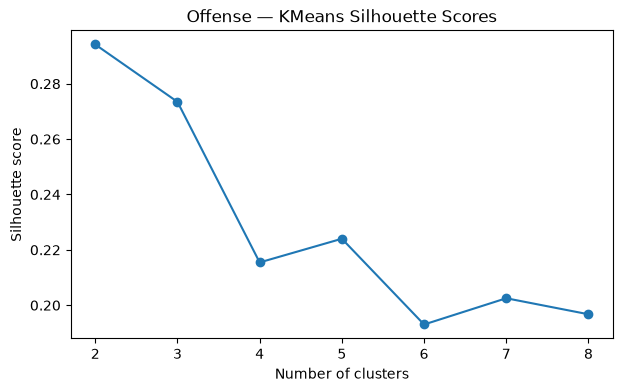

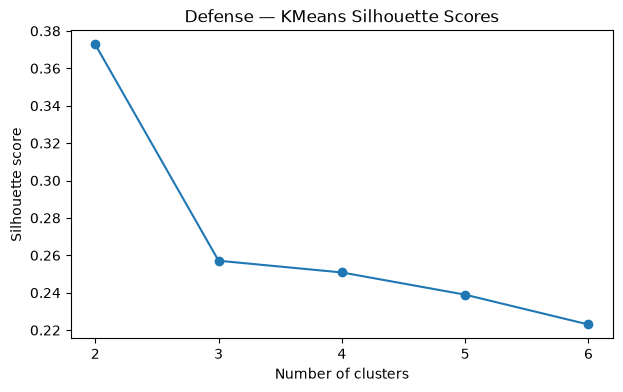

In [139]:
import matplotlib.pyplot as plt

for name in ["Offense", "Defense"]:

    subset = cluster_results[
        cluster_results["Model"] == name
    ]

    plt.figure(figsize=(7, 4))

    plt.plot(
        subset["k"],
        subset["Silhouette"],
        marker="o",
    )

    plt.title(f"{name} — KMeans Silhouette Scores")
    plt.xlabel("Number of clusters")
    plt.ylabel("Silhouette score")
    plt.xticks(subset["k"])

    plt.show()

In [140]:
def inspect_clusters(X, player_names, k):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X)

    results = X.reset_index(drop=True).copy()
    results["PLAYER_NAME"] = player_names.reset_index(drop=True)
    results["cluster"] = labels

    # Average dimension scores for each cluster.
    profiles = (
        results.groupby("cluster")[list(X.columns)]
        .mean()
        .T
        .round(2)
    )

    # Number of players per cluster.
    sizes = (
        results["cluster"]
        .value_counts()
        .sort_index()
    )

    # Distance from each player to their assigned centroid.
    distances = model.transform(X)

    results["distance_to_centroid"] = distances[
        np.arange(len(X)), labels
    ]

    # Five representative players closest to each centroid.
    representatives = (
        results.sort_values("distance_to_centroid")
        .groupby("cluster")
        .head(5)[
            ["cluster", "PLAYER_NAME", "distance_to_centroid"]
        ]
        .sort_values(["cluster", "distance_to_centroid"])
    )

    return profiles, sizes, representatives

In [147]:
offense_profiles_3, offense_sizes_3, offense_players_3 = (
    inspect_clusters(
        X_offense,
        log_scores["PLAYER_NAME"],
        k=7,
    )
)

display(offense_sizes_3)
display(offense_profiles_3)
display(offense_players_3)

cluster
0    29
1    97
2    58
3    63
4    53
5    80
6    70
Name: count, dtype: int64

cluster,0,1,2,3,4,5,6
Ball Dominance,0.72,-0.72,-0.92,1.67,0.61,-0.71,0.32
Playmaking,0.44,-0.64,-0.71,1.56,0.95,-0.59,-0.14
Ball Movement,-0.67,0.25,0.13,-0.56,1.14,0.25,-0.83
Rim Pressure,1.32,-0.38,-0.08,1.39,-0.31,-1.12,0.29
On-Ball Creation,0.24,-0.73,-0.90,1.60,0.56,-0.61,0.48
Perimeter Shooting,-1.05,0.23,-1.59,-0.37,0.26,1.16,0.24
Interior Offense,1.52,0.18,1.57,-0.63,-0.72,-0.66,-0.32
Offensive Rebounding,-0.12,0.55,1.48,-0.59,-0.42,-0.46,-0.57


,cluster,PLAYER_NAME,distance_to_centroid
210,0,Jimmy Butler III,1.125589
11,0,Alex Sarr,1.140483
132,0,Evan Mobley,1.379276
239,0,Julius Randle,1.384113
103,0,Derik Queen,1.522503
270,1,Kobe Brown,0.541063
161,1,Jabari Walker,0.803717
104,1,Derrick Jones Jr.,0.820805
185,1,Jamir Watkins,0.960158
388,1,Santi Aldama,0.995261


In [145]:
defense_profiles_4, defense_sizes_4, defense_players_4 = (
    inspect_clusters(
        X_defense,
        log_scores["PLAYER_NAME"],
        k=4,
    )
)

display(defense_profiles_4)
display(defense_players_4)

cluster,0,1,2,3
Defensive Disruption,0.57,-0.91,-0.31,0.70
Perimeter Defense,1.27,0.04,-1.12,-0.15
Interior Defense,-0.90,-0.50,1.38,0.06
Defensive Rebounding,-0.64,-0.45,1.30,-0.15


,cluster,PLAYER_NAME,distance_to_centroid
94,0,De'Aaron Fox,0.227350
114,0,Donovan Mitchell,0.235151
77,0,Collin Gillespie,0.339262
343,0,Norman Powell,0.387186
366,0,Quenton Jackson,0.443581
319,1,Mohamed Diawara,0.352482
28,1,Ayo Dosunmu,0.364188
298,1,Malaki Branham,0.422025
270,1,Kobe Brown,0.477935
0,1,AJ Green,0.546823


In [148]:
predictors = X_offense[
    ["Playmaking", "On-Ball Creation"]
]

target = X_offense["Ball Dominance"]

regression = LinearRegression()
regression.fit(predictors, target)

print(
    "Ball Dominance R²:",
    round(regression.score(predictors, target), 3)
)

Ball Dominance R²: 0.843


In [151]:
from sklearn.metrics import adjusted_rand_score
X_without_bd = X_offense.drop(
    columns=["Ball Dominance"]
)

models = {
    "Original": X_offense,
    "Without Ball Dominance": X_without_bd,
}

labels = {}

for name, X in models.items():
    model = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=20,
    )

    labels[name] = model.fit_predict(X)

    print(name)
    print("Silhouette:", round(
        silhouette_score(X, labels[name]), 3
    ))

    print(
        pd.Series(labels[name])
        .value_counts()
        .sort_index()
    )

ari = adjusted_rand_score(
    labels["Original"],
    labels["Without Ball Dominance"],
)

print("Adjusted Rand Index:", round(ari, 3))

Original
Silhouette: 0.224
0     77
1     67
2     70
3     74
4    162
Name: count, dtype: int64
Without Ball Dominance
Silhouette: 0.209
0     71
1     80
2    151
3     80
4     68
Name: count, dtype: int64
Adjusted Rand Index: 0.871


In [152]:
new_profiles = (
    X_offense.assign(
        cluster=labels["Without Ball Dominance"]
    )
    .groupby("cluster")
    .mean()
    .T
)

display(new_profiles.round(2))

cluster,0,1,2,3,4
Ball Dominance,1.54,-0.70,-0.74,0.24,0.58
Playmaking,1.42,-0.61,-0.63,-0.21,0.87
Ball Movement,-0.64,0.01,0.32,-0.90,1.01
Rim Pressure,1.55,0.10,-0.79,0.17,-0.19
On-Ball Creation,1.46,-0.79,-0.72,0.37,0.58
Perimeter Shooting,-0.58,-1.38,0.76,0.30,0.18
Interior Offense,-0.26,1.51,-0.23,-0.21,-0.75
Offensive Rebounding,-0.52,1.15,0.12,-0.56,-0.41


In [153]:
new_profiles, new_sizes, new_representatives = inspect_clusters(
    X_without_bd,
    log_scores["PLAYER_NAME"],
    k=5,
)

display(new_representatives)

player_comparison = log_scores[
    ["PLAYER_ID", "PLAYER_NAME"]
].reset_index(drop=True).copy()

player_comparison["original_cluster"] = labels["Original"]
player_comparison["new_cluster"] = labels["Without Ball Dominance"]

# How original clusters map to the new clusters.
overlap = pd.crosstab(
    player_comparison["original_cluster"],
    player_comparison["new_cluster"],
)

display(overlap)

,cluster,PLAYER_NAME,distance_to_centroid
94,0,De'Aaron Fox,0.997254
45,0,Brandon Williams,1.005265
8,0,Ajay Mitchell,1.014437
429,0,Tyrese Maxey,1.015844
27,0,Austin Reaves,1.109272
330,1,Neemias Queta,0.807905
304,1,Marvin Bagley III,0.900241
153,1,Isaiah Jackson,0.907529
377,1,Rudy Gobert,0.995045
296,1,Luke Kornet,1.032835


new_cluster,0,1,2,3,4
original_cluster,,,,,
0,3,5,0,69,0
1,66,0,0,1,0
2,2,1,0,3,64
3,0,74,0,0,0
4,0,0,151,7,4


In [154]:
cluster_mapping = overlap.idxmax(axis=0).to_dict()

print("New to original cluster mapping:")
print(cluster_mapping)

# Check that the mapping is one-to-one.
assert len(set(cluster_mapping.values())) == len(cluster_mapping)

player_comparison["matched_original"] = (
    player_comparison["new_cluster"].map(cluster_mapping)
)

changed_players = player_comparison[
    player_comparison["original_cluster"]
    != player_comparison["matched_original"]
]

print("Players changing groups:", len(changed_players))

display(
    changed_players[
        ["PLAYER_NAME", "original_cluster", "new_cluster"]
    ].sort_values(["original_cluster", "new_cluster"])
)

New to original cluster mapping:
{0: 1, 1: 3, 2: 4, 3: 0, 4: 2}
Players changing groups: 26


,PLAYER_NAME,original_cluster,new_cluster
97,DeMar DeRozan,0,0
106,Desmond Bane,0,0
133,Franz Wagner,0,0
11,Alex Sarr,0,1
21,Anthony Davis,0,1
132,Evan Mobley,0,1
245,Karl-Anthony Towns,0,1
320,Moritz Wagner,0,1
398,Stephen Curry,1,3
255,Kennedy Chandler,2,0


In [158]:
pullup_share = (
    log_scores["PULL_UP_FGA"]
    / log_scores["FGA"]
)

# Build an alternative On-Ball Creation composite.
inputs = pd.DataFrame({
    "PULL_UP_SHARE": pullup_share,
    "PCT_UAST_FGM": log_scores["PCT_UAST_FGM"],
})

assert inputs.notna().all().all()
assert inputs["PULL_UP_SHARE"].between(0, 1).all()

scaler = StandardScaler()
standardized = scaler.fit_transform(inputs)

composite = standardized.mean(axis=1)

# Standardize the finished composite.
new_creation_score = StandardScaler().fit_transform(
    composite.reshape(-1, 1)
).ravel()

# Keep the other six dimensions unchanged.
X_style = X_without_bd.copy()

X_style["On-Ball Creation"] = new_creation_score

# Compare against the previous seven-dimension model.
model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20,
)

style_labels = model.fit_predict(X_style)

print(
    "Silhouette:",
    round(silhouette_score(X_style, style_labels), 3)
)

print(
    "ARI:",
    round(
        adjusted_rand_score(
            labels["Without Ball Dominance"],
            style_labels,
        ),
        3,
    )
)

Silhouette: 0.206
ARI: 0.935


In [159]:
style_profiles, style_sizes, style_players = (
    inspect_clusters(
        X_style,
        log_scores["PLAYER_NAME"],
        k=5,
    )
)

display(style_sizes)
display(style_profiles)
display(style_players)

cluster
0     77
1     69
2     64
3    156
4     84
Name: count, dtype: int64

cluster,0,1,2,3,4
Playmaking,-0.21,1.43,0.93,-0.60,-0.59
Ball Movement,-0.91,-0.67,0.96,0.36,-0.01
Rim Pressure,0.14,1.57,-0.15,-0.76,0.12
On-Ball Creation,0.29,1.42,0.78,-0.73,-0.67
Perimeter Shooting,0.33,-0.56,0.15,0.74,-1.34
Interior Offense,-0.29,-0.26,-0.80,-0.22,1.50
Offensive Rebounding,-0.58,-0.53,-0.46,0.12,1.10


,cluster,PLAYER_NAME,distance_to_centroid
95,0,De'Andre Hunter,0.648100
421,0,Trey Murphy III,0.686696
334,0,Nickeil Alexander-Walker,0.770360
221,0,Jordan Clarkson,0.824256
440,0,Will Riley,0.843995
429,1,Tyrese Maxey,0.996732
94,1,De'Aaron Fox,1.015940
45,1,Brandon Williams,1.026095
8,1,Ajay Mitchell,1.077806
178,1,Jalen Williams,1.098805


In [160]:
comparison = pd.crosstab(
    pd.Series(
        labels["Without Ball Dominance"],
        name="Pull-up FGA/100"
    ),
    pd.Series(
        style_labels,
        name="Pull-up FGA Share"
    ),
)

display(comparison)

Pull-up FGA Share,0,1,2,3,4
Pull-up FGA/100,,,,,
0,0,69,1,0,1
1,0,0,0,0,80
2,1,0,0,150,0
3,76,0,0,1,3
4,0,0,63,5,0


In [162]:
usage_summary = pd.DataFrame({
    "cluster": labels["Without Ball Dominance"],
    "USG_PCT": log_scores["USG_PCT"].to_numpy(),
})

display(
    usage_summary.groupby("cluster")["USG_PCT"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

,count,mean,median,min,max
cluster,,,,,
0,71,0.26,0.26,0.19,0.37
1,80,0.16,0.15,0.08,0.27
2,151,0.15,0.15,0.08,0.22
3,80,0.22,0.21,0.16,0.34
4,68,0.17,0.17,0.10,0.26


In [163]:
usage_comparison = X_without_bd.reset_index(drop=True).copy()

usage_comparison["PLAYER_NAME"] = (
    log_scores["PLAYER_NAME"].to_numpy()
)

usage_comparison["USG_PCT"] = (
    log_scores["USG_PCT"].to_numpy()
)

usage_comparison["cluster"] = (
    labels["Without Ball Dominance"]
)

# Keep players with similar offensive usage.
similar_usage = usage_comparison[
    usage_comparison["USG_PCT"].between(0.18, 0.22)
]

# Number of players and average usage in each cluster.
display(
    similar_usage.groupby("cluster").agg(
        players=("PLAYER_NAME", "count"),
        mean_usage=("USG_PCT", "mean"),
    ).round(3)
)

# Compare playing-style dimensions within this usage range.
display(
    similar_usage.groupby("cluster")[
        X_without_bd.columns.tolist()
    ].mean().round(2)
)

,players,mean_usage
cluster,,
0,13,0.204
1,11,0.193
2,23,0.188
3,35,0.202
4,24,0.197


,Playmaking,Ball Movement,Rim Pressure,On-Ball Creation,Perimeter Shooting,Interior Offense,Offensive Rebounding
cluster,,,,,,,
0,1.19,0.44,1.61,0.93,-0.86,-0.55,-0.42
1,-0.44,-0.42,0.28,-0.78,-1.06,1.71,0.58
2,-0.51,-0.08,-0.36,-0.68,0.83,0.13,0.08
3,-0.24,-0.63,0.03,0.27,0.24,-0.24,-0.49
4,0.95,0.63,0.04,0.96,0.27,-0.84,-0.32


In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances
from nba_archetypes.config import PROCESSED_DATA_DIR


players = pd.read_parquet(
    PROCESSED_DATA_DIR / "player_style_features.parquet"
).reset_index(drop=True)


offensive_dimensions = [
    "BALL_DOMINANCE",
    "PLAYMAKING",
    "BALL_MOVEMENT",
    "RIM_PRESSURE",
    "ON_BALL_CREATION",
    "PERIMETER_SHOOTING",
    "INTERIOR_OFFENSE",
    "OFFENSIVE_REBOUNDING",
]

defensive_dimensions = [
    "DEFENSIVE_DISRUPTION",
    "PERIMETER_DEFENSE",
    "INTERIOR_DEFENSE",
    "DEFENSIVE_REBOUNDING",
]

offense_cols = [
    f"{dim}_SCORE" for dim in offensive_dimensions
]

defense_cols = [
    f"{dim}_SCORE" for dim in defensive_dimensions
]

offense_dist = pairwise_distances(
    players[offense_cols],
    metric="cosine",
) / np.sqrt(len(offense_cols))


# Defensive distances.
defense_dist = pairwise_distances(
    players[defense_cols],
    metric="cosine",
) / np.sqrt(len(defense_cols))


# Balanced overall distance.
overall_dist = np.sqrt(
    0.5 * offense_dist**2
    + 0.5 * defense_dist**2
)


distances = {
    "offense": offense_dist,
    "defense": defense_dist,
    "overall": overall_dist,
}

In [15]:
def find_similar_players(player_name, similarity_type="overall", n=10):

    matches = players.index[
        players["PLAYER_NAME"] == player_name
    ]

    if len(matches) != 1:
        raise ValueError(
            "Player name must match exactly one player."
        )

    player_idx = matches[0]

    # Select the requested distance matrix.
    matrix = distances[similarity_type]

    # Distance from this player to everyone else.
    player_distances = matrix[player_idx].copy()

    # Exclude the player from their own results.
    player_distances[player_idx] = np.inf

    # Find the nearest neighbors.
    nearest_indices = np.argsort(player_distances)[:n]

    results = players.iloc[nearest_indices][
        ["PLAYER_ID", "PLAYER_NAME"]
    ].copy()

    results["DISTANCE"] = player_distances[nearest_indices]

    return results.reset_index(drop=True)

In [37]:
display(
    find_similar_players(
        "Jaylen Brown",
        similarity_type="offense",
        n=10,
    )
)

,PLAYER_ID,PLAYER_NAME,DISTANCE
0,1628983,Shai Gilgeous-Alexander,0.008424
1,1626164,Devin Booker,0.010236
2,1631101,Shaedon Sharpe,0.016696
3,1630224,Jalen Green,0.021254
4,202695,Kawhi Leonard,0.023545
5,1630560,Cam Thomas,0.024548
6,1628378,Donovan Mitchell,0.025513
7,203944,Julius Randle,0.026578
8,1629012,Collin Sexton,0.026800
9,1627742,Brandon Ingram,0.027404
